# PALM-bulk: real-data workflow

Bayesian inference (CPU or GPU) of **cell fractions**, **per-cell-type program activity**, and **which cell types carry each program** from bulk RNA-seq, using an annotated scRNA-seq reference.

**How to use**
1. Leave `USE_DEMO = True` and run all cells once. It simulates data in the exact file formats below, so you can see the whole flow work.
   (The demo fit takes about 3-5 minutes on a laptop CPU.)
2. Put your files in `data/`, set `USE_DEMO = False`, edit the config cell, and run again.
3. For hundreds of bulk samples, read **Compute** in section 2 first: on CPU a full fit can take a day.

**Files you need**
| File | Format |
|---|---|
| Reference scRNA-seq | `.h5ad`, **raw counts** in `.X` (or a layer), `obs` columns for cell type and (ideally) donor |
| Bulk counts | CSV, **genes x samples**, raw integer counts, gene symbols in the first column |
| Bulk metadata (optional) | CSV, index = sample IDs; a condition column if you want treatment effects |
| Programs (optional) | CSV long format with columns `program, gene, weight`; if omitted, PROGENy is fetched via `decoupler` |

Use the same gene identifiers (e.g. symbols) in all three.

## 1. Setup

In [1]:
import warnings, time, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import palm_bulk as pb
from palm_bulk import plots, sim
from IPython.display import display
warnings.filterwarnings("ignore", category=FutureWarning)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Configuration
Edit this cell only.  `CONDITION_COL = None` runs a descriptive analysis (fractions, program activity, attribution per sample).
Setting a condition column adds the **treatment-effect decomposition** (intrinsic vs composition-driven change). That decomposition is only causal if treatment is randomised or otherwise ignorable, see the notes at the end.

**Compute (speed only, the model and its results are unchanged)**
* `DEVICE = "gpu"` runs the same sampler on an NVIDIA GPU. Needs Linux or WSL2 and a CUDA build of JAX:
  `pip install "palm-bulk[gpu]"` (on Colab: *Runtime > Change runtime type > GPU*). `"auto"` uses a GPU when one is visible, else CPU.
* `PARALLEL_CHAINS` lets several chains run at once on CPU. Set it equal to `CHAINS`.
  On a large problem one chain already uses every CPU core, so on a typical workstation this gives **little or no speed-up**.
  It helps on small problems and on many-core servers. On a GPU, chains are batched automatically and this setting is not needed.
* Device settings apply only before JAX starts. If you change them after running a fit, **restart the kernel** and run from the top.
* Draws are not bit-identical across devices or chain methods (floating-point rounding differs), but the posterior is the same.

Measured cost of one gradient on a 12-core laptop CPU (P = 14 programs, 1500 genes). NUTS needs roughly 500-1000 gradients per iteration:

| Bulk samples x cell types | ms per gradient | est. time, 1 chain, 400+400 iterations |
|---|---|---|
| 16 x 4 (demo) | 0.8 | ~3 min |
| 500 x 10 | 100 | ~11-22 h |
| 500 x 20 | 150 | ~17-34 h |

The scRNA-seq reference size (number of cells) barely matters: it is collapsed to one profile per cell type before fitting.

In [2]:
USE_DEMO = True                       # <- set False for your own data

# ---- your files (used when USE_DEMO = False) ----
REF_H5AD       = "data/reference.h5ad"
CELLTYPE_KEY   = "cell_type"          # adata.obs column with cell-type labels
DONOR_KEY      = "donor"              # adata.obs column with donor IDs, or None
COUNTS_LAYER   = None                 # None -> adata.X holds raw counts
BULK_CSV       = "data/bulk_counts.csv"
META_CSV       = "data/bulk_metadata.csv"   # or None
CONDITION_COL  = "condition"          # column in META_CSV, or None for descriptive mode
CONTROL_LABEL  = "control"            # value of the control arm
PROGRAMS_CSV   = "data/programs.csv"  # or None -> PROGENy via decoupler (needs internet)

# ---- model ----
MAX_GENES      = 1500                 # union of program genes, markers, HVGs, anchors; runtime grows linearly with this
USE_PLATFORM_SCALE = True             # gene-wise platform bias term m_g (recommended for real data)
NUM_WARMUP, NUM_SAMPLES, CHAINS = 400, 400, 1   # use CHAINS=2+ for R-hat
OUTDIR = "results"

# ---- compute (speed only; see the notes above) ----
DEVICE          = "cpu"               # "cpu", "gpu" or "auto" (GPU if available)
PARALLEL_CHAINS = 1                   # CPU: chains run at the same time; set = CHAINS to enable

# Must run before the first JAX computation; after changing it, restart the kernel.
print("compute:", pb.configure_compute(DEVICE, parallel_chains=PARALLEL_CHAINS))

## 3. Load data
In demo mode this first *writes* synthetic files to `data_demo/` (a hidden ground truth is kept for a recovery check at the end), then loads them through the same code path your real files will use.

In [3]:
if USE_DEMO:
    import anndata as ad
    os.makedirs("data_demo", exist_ok=True)
    rng = np.random.default_rng(7)
    B_true, G_true = sim.make_reference(rng, C=4, P=3, Gn=400, genes_per_prog=30)
    genes = ["GENE%d" % i for i in range(400)]
    types = np.array(["CD8_T", "Monocyte", "B_cell", "Fibroblast"])
    counts, ct, dn = sim.simulate_reference_cells(rng, B_true, n_per_type=400, n_donors=4, depth=3000)
    adata = ad.AnnData(X=counts.astype("float32"), obs=pd.DataFrame(
        {"cell_type": types[ct], "donor": ["D%d" % d for d in dn]}), var=pd.DataFrame(index=genes))
    adata.write_h5ad("data_demo/reference.h5ad")
    s = sim.simulate_causal(rng, B_true, G_true, N=16)
    samples = ["S%02d" % i for i in range(16)]
    pd.DataFrame(s["Y"].T, index=pd.Index(genes, name="gene"), columns=samples).to_csv("data_demo/bulk_counts.csv")
    pd.DataFrame({"condition": np.where(s["T"] == 1, "treated", "control")}, index=samples).to_csv("data_demo/bulk_metadata.csv")
    pr_names = ["IFN_like", "TGFb_like", "Hypoxia_like"]
    long = [(pn, genes[g], G_true[p, g]) for p, pn in enumerate(pr_names)
            for g in np.nonzero(G_true[p])[0]]
    pd.DataFrame(long, columns=["program", "gene", "weight"]).to_csv("data_demo/programs.csv", index=False)
    demo_truth = s
    REF_H5AD, BULK_CSV, META_CSV, PROGRAMS_CSV = ("data_demo/reference.h5ad", "data_demo/bulk_counts.csv",
                                                   "data_demo/bulk_metadata.csv", "data_demo/programs.csv")
    CELLTYPE_KEY, DONOR_KEY, COUNTS_LAYER, CONDITION_COL, CONTROL_LABEL = "cell_type", "donor", None, "condition", "control"
    NUM_WARMUP, NUM_SAMPLES = 250, 250
    print("demo files written to data_demo/")

import anndata as ad
adata = ad.read_h5ad(REF_H5AD)
ref = pb.from_anndata(adata, CELLTYPE_KEY, DONOR_KEY, layer=COUNTS_LAYER)
bulk = pd.read_csv(BULK_CSV, index_col=0)
meta = pd.read_csv(META_CSV, index_col=0) if META_CSV else None

if PROGRAMS_CSV:
    programs = pb.load_programs(PROGRAMS_CSV)
else:
    import decoupler as dc            # pip install "palm-bulk[progeny]"
    try:
        net = dc.op.progeny(organism="human", top=500)      # decoupler >= 2
    except AttributeError:
        net = dc.get_progeny(organism="human", top=500)     # decoupler 1.x
    programs = pb.load_programs(net.rename(columns={"source": "program", "target": "gene"}))

T = None
if CONDITION_COL:
    T = (meta.loc[bulk.columns, CONDITION_COL] != CONTROL_LABEL).astype(int).values

print("reference:", adata.n_obs, "cells,", adata.n_vars, "genes")
print("bulk:", bulk.shape[1], "samples,", bulk.shape[0], "genes")
print("programs:", list(programs.index))
if T is not None:
    print("arms: control =", int((T == 0).sum()), " treated =", int((T == 1).sum()))

/usr/lib/python3.12/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


demo files written to data_demo/
reference: 1600 cells, 400 genes
bulk: 16 samples, 400 genes
programs: ['Hypoxia_like', 'IFN_like', 'TGFb_like']
arms: control = 8  treated = 8


## 4. Reference summary and bulk quality checks

In [4]:
display(pd.DataFrame({"n_cells": ref.n_cells, "n_donors": ref.n_donors,
                      "mean_UMI_per_cell": ref.rna_content.round(0)}, index=ref.cell_types))
lib = bulk.sum(0)
print("bulk library size: min %.0f, median %.0f, max %.0f" % (lib.min(), lib.median(), lib.max()))
print("gene overlap bulk/reference: %d / %d" % (len(set(bulk.index) & set(ref.genes)), len(ref.genes)))

,n_cells,n_donors,mean_UMI_per_cell
B_cell,400,4,3001.0
CD8_T,400,4,3002.0
Fibroblast,400,4,2999.0
Monocyte,400,4,2997.0


bulk library size: min 196076, median 201800, max 206562
gene overlap bulk/reference: 400 / 400


/tmp/ipykernel_641/75966647.py:3: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  lib = bulk.sum(0)


## 5. Prepare model inputs
Aligns genes and picks `MAX_GENES` modelled genes as a **union of four sets**, each serving one part of the model:

| Set | Default share | Role in the model |
|---|---|---|
| Program genes | 45% | top genes of each program by \|weight\|, taken in turn so every program is represented: program activity and attribution |
| Cell-type markers | 30% | genes specific to each cell type, taken in turn per type: cell fractions, so program signal is not mistaken for composition |
| Highly variable genes | 10% | most variable across reference cells: cell-state variation that markers miss |
| Anchor genes | 15% | well expressed, similar in all cell types, no program weight: keep normalisation stable when programs are induced |

Genes must be expressed in the reference (the model can only scale a gene's baseline, so a gene absent from the reference cannot be induced) and detected in at least 20% of bulk samples.
Unused budget from one set passes to the others. Change the shares with `prepare_inputs(..., gene_budget={"programs": 0.5, ...})`.
Check `gene_sets` below: every program should keep a reasonable number of genes and every cell type some markers.

Then the reference baseline is renormalised on the modelled genes.

**Compatibility check:** each bulk profile is fit with non-negative least squares on the reference baselines.
Samples with a low R² or low `log_corr` are either strongly induced (program activity, expected) or point to a **missing cell type** or heavy **platform bias**. Check which before trusting attribution.

In [5]:
inp = pb.prepare_inputs(bulk, ref, programs, treatment=T, max_genes=MAX_GENES)
gs = inp.info.pop("gene_sets")
print(inp.info)
print("gene sets:", gs["sizes"], "| eligible genes:", gs["n_eligible"],
      "| program genes available:", gs["program_genes_available"])
print("markers per cell type:", gs["markers_per_type"])
diag = pb.diagnose_inputs(inp)
display(diag.describe().loc[["min", "50%", "max"]].round(3))

{'n_genes': 400, 'n_programs_in': 3, 'n_programs_kept': 3, 'program_genes_present': {'Hypoxia_like': 30, 'IFN_like': 30, 'TGFb_like': 30}, 'n_samples': 16, 'min_library': 196076.0}


,r2,log_corr,mass_explained
min,0.513,0.947,0.964
50%,0.772,0.974,1.009
max,0.961,0.989,1.045


## 6. Fit the Bayesian model (NUTS, CPU or GPU)
With `CHAINS > 1`, `chain_method="auto"` picks how chains are scheduled: in parallel if `PARALLEL_CHAINS` made enough CPU devices,
batched on a GPU, otherwise one after another. Set it explicitly (`"sequential"`, `"parallel"`, `"vectorized"`) to override.

In [6]:
t0 = time.time()
res = pb.run_palm(inp, use_m=USE_PLATFORM_SCALE, num_warmup=NUM_WARMUP, num_samples=NUM_SAMPLES, chains=CHAINS,
                  chain_method="auto")
print("fit time: %.0fs" % (time.time() - t0))
print(res.diagnostics())

fit time: 268s
{'divergences': 0, 'n_draws': 250}


**Sampler checks:** `divergences` should be 0 (a handful is tolerable; many means the posterior is unreliable, so reduce programs/genes or raise warmup).
With `CHAINS >= 2`, `rhat_max` should be below 1.01. `platform` and `chain_method` show where and how the fit ran.

## 7. Cell fractions

,B_cell,CD8_T,Fibroblast,Monocyte
S00,0.506,0.251,0.125,0.117
S01,0.334,0.162,0.492,0.012
S02,0.341,0.229,0.210,0.220
S03,0.348,0.130,0.512,0.010
S04,0.337,0.223,0.429,0.008
S05,0.297,0.154,0.541,0.009
S06,0.453,0.111,0.292,0.145
S07,0.567,0.076,0.351,0.008
S08,0.211,0.245,0.322,0.220
S09,0.422,0.151,0.414,0.011


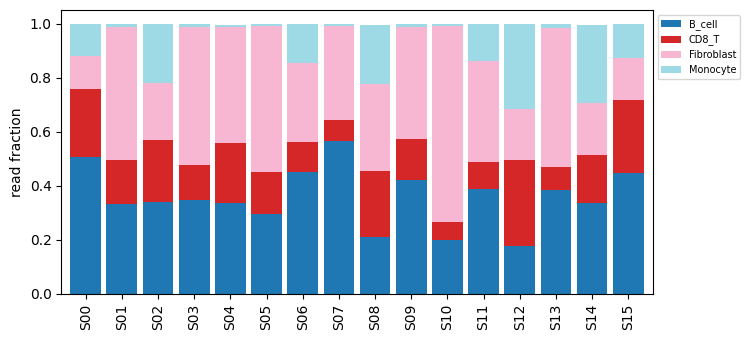

In [7]:
f = res.fractions()
display(f["median"].round(3).head(10))
plots.plot_fractions(res); plt.tight_layout(); plt.show()

`cell_fractions()` converts read fractions to cell fractions by dividing by the reference RNA content per cell type.

In [8]:
display(res.cell_fractions()["median"].round(3).head(10))

,B_cell,CD8_T,Fibroblast,Monocyte
S00,0.506,0.251,0.125,0.117
S01,0.334,0.162,0.492,0.012
S02,0.341,0.229,0.210,0.220
S03,0.348,0.130,0.512,0.010
S04,0.337,0.223,0.429,0.009
S05,0.297,0.154,0.542,0.009
S06,0.453,0.111,0.292,0.145
S07,0.566,0.076,0.351,0.008
S08,0.211,0.245,0.322,0.220
S09,0.422,0.151,0.414,0.011


## 8. Program activity and attribution
`program_activity()`: induced program signal per sample (relative to each cell type's reference state).
`attribution()`: for each sample and program, the **share of that signal carried by each cell type**, with credible intervals. Wide intervals mean the data cannot tell the cell types apart for that program.

program,Hypoxia_like,IFN_like,TGFb_like
sample,,,
S00,-0.0039,0.0037,0.0137
S01,0.0683,0.0903,0.1498
S02,0.0050,0.0196,0.0101
S03,0.0696,0.0896,0.1279
S04,0.0712,0.0955,0.1408
S05,0.0442,0.1164,0.1627
S06,0.0035,0.0111,-0.0055
S07,0.0832,0.0540,0.1631


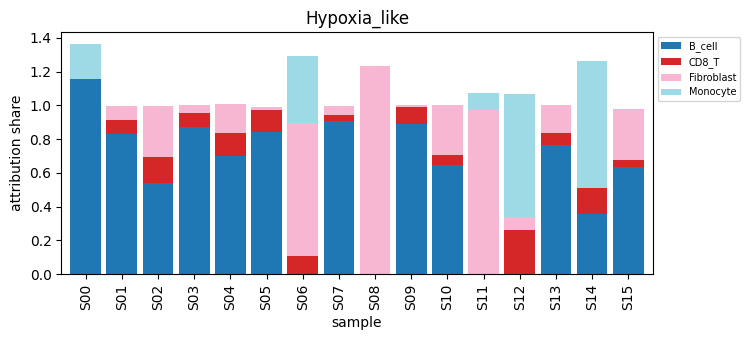

median attribution for Hypoxia_like


,share,share_lo,share_hi
cell_type,,,
B_cell,0.67,0.38,0.96
Fibroblast,0.12,-0.03,0.55
CD8_T,0.08,-0.05,0.17
Monocyte,-0.00,-0.05,0.10


In [9]:
act = res.program_activity()
display(act.pivot(index="sample", columns="program", values="activity").round(4).head(8))
attr = res.attribution()
prog0 = res.inputs.programs[0]
plots.plot_attribution(res, prog0); plt.tight_layout(); plt.show()
top = (attr[attr.program == prog0].groupby("cell_type")[["share", "share_lo", "share_hi"]].median().round(2)
       .sort_values("share", ascending=False))
print("median attribution for", prog0); display(top)

## 9. Treatment effects: intrinsic vs composition (needs a condition column)
For each program, the bulk change between arms is split exactly into
* **intrinsic**: cells of a type respond differently under treatment;
* **composition**: treatment changes which cell types are present.

The split is a Shapley average over the two orderings, so the parts add up to the total.

,program,total,intrinsic,intrinsic_lo,intrinsic_hi,composition,composition_lo,composition_hi
0,Hypoxia_like,0.0442,0.0417,0.0296,0.0566,0.0030,-0.0072,0.0120
1,IFN_like,0.0566,0.0598,0.0469,0.0757,-0.0037,-0.0184,0.0090
2,TGFb_like,0.1134,0.1044,0.0828,0.1310,0.0098,-0.0137,0.0238


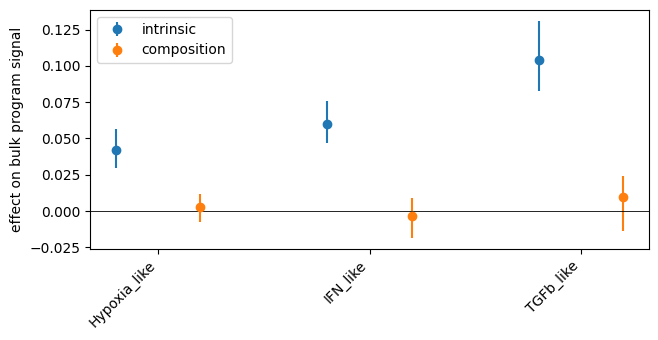

Share of each program's intrinsic effect by cell type:


cell_type,B_cell,CD8_T,Fibroblast,Monocyte
program,,,,
Hypoxia_like,1.14,0.12,-0.23,-0.05
IFN_like,-0.22,0.49,0.69,0.02
TGFb_like,0.43,-0.00,0.61,-0.04


In [10]:
if res.has_treatment:
    totals = res.effect_totals()
    display(totals[["program", "total", "intrinsic", "intrinsic_lo", "intrinsic_hi",
                    "composition", "composition_lo", "composition_hi"]].round(4))
    plots.plot_effects(res); plt.tight_layout(); plt.show()
    print("Share of each program's intrinsic effect by cell type:")
    display(res.intrinsic_shares().pivot(index="program", columns="cell_type", values="share").round(2))
else:
    print("No condition column set: skipping.")

## 10. Demo only: recovery of the hidden ground truth

In [11]:
if USE_DEMO:
    # NOTE: palm_bulk sorts cell types and programs alphabetically; always align by NAME, never by position.
    ct_idx = [list(types).index(c) for c in res.inputs.cell_types]
    pr_idx = [pr_names.index(p) for p in res.inputs.programs]
    pi_hat = res.fractions()["median"].values
    print("read-fraction RMSE: %.3f" % np.sqrt(((pi_hat - demo_truth["pi"][:, ct_idx]) ** 2).mean()))
    t = res.effect_totals()
    print(pd.DataFrame({"program": t.program,
                        "intrinsic_true": demo_truth["truth"]["I"].sum(0)[pr_idx], "intrinsic_est": t.intrinsic,
                        "composition_true": demo_truth["truth"]["K"].sum(0)[pr_idx], "composition_est": t.composition
                        }).round(4).to_string(index=False))
else:
    print("Skipped (real data has no ground truth).")

read-fraction RMSE: 0.013
     program  intrinsic_true  intrinsic_est  composition_true  composition_est
Hypoxia_like          0.0394         0.0417            0.0022           0.0030
    IFN_like          0.0668         0.0598           -0.0076          -0.0037
   TGFb_like          0.1127         0.1044            0.0129           0.0098


## 11. Export

In [12]:
res.save(OUTDIR)
print(sorted(os.listdir(OUTDIR)))

['attribution.csv', 'intrinsic_shares.csv', 'program_activity.csv', 'read_fractions.csv', 'read_fractions_hi.csv', 'read_fractions_lo.csv', 'treatment_effect_totals.csv', 'treatment_effects.csv']


## Notes and limits
* **Raw counts only** for both reference and bulk (not TPM/FPKM, not log-normalised).
* **Missing cell types** in the reference load onto the cell types that are present. Attribution is only as good as the reference's coverage; use the compatibility check in section 5.
* **Causal reading** of section 9 needs randomised (or otherwise ignorable) treatment, a reference that represents the baseline state of each cell type, and a correct program dictionary. Observational cohorts: treat the decomposition as descriptive.
* **Which cell type drives which** (e.g. T cells inducing interferon in macrophages) is *not* identifiable from bulk data; this method attributes where a program is expressed, not what caused it.
* **Shared programs** (genes expressed alike across cell types) give wide attribution intervals by design.
* Cell types and programs appear in **alphabetical order** in all outputs (`res.inputs.cell_types`, `res.inputs.programs`); align with other tables by name.
* Run time grows with samples x genes x cell types x programs (not with the number of reference cells). For hundreds of samples use a GPU (section 2). On CPU, start with `MAX_GENES = 1000` and a handful of programs.